# Day 11: Classification Using Scikit-learn

## Introduction

Classification is a supervised machine learning task in which a model learns from labelled examples and predicts a category for new observations. Unlike regression, which predicts a numerical value, classification predicts a discrete class such as Pass/Fail, Spam/Not Spam, or a flower species.

In this task, the **Iris dataset** is used to build and compare two classification algorithms: Logistic Regression and Decision Tree Classifier.

The dataset contains measurements of three Iris flower species: *Iris-setosa*, *Iris-versicolor*, and *Iris-virginica*. Each flower is described using four numerical features:

- **Sepal Length:** Length of the sepal in centimetres.
- **Sepal Width:** Width of the sepal in centimetres.
- **Petal Length:** Length of the petal in centimetres.
- **Petal Width:** Width of the petal in centimetres.

### Objectives

1. Understand the basic concept of classification and its application.
2. Load and prepare the Iris dataset for machine learning.
3. Divide the dataset into training and testing sets.
4. Train Logistic Regression and Decision Tree classification models.
5. Evaluate both models using accuracy and classification metrics.
6. Compare their performance and record observations based on the actual results.

## 1. Loading Libraries and Dataset
We import Pandas, Matplotlib, and Scikit-learn, then load the `Iris.csv` dataset.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
from pathlib import Path

# Load the dataset
data = pd.read_csv("Iris.csv")
data.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


## 2. Data Preprocessing
We clean and prepare the dataset:
- Drop the unnecessary `Id` column.
- Check for missing values.
- Inspect and remove duplicate rows to ensure clean training data.
- Separate features (`features`) and target (`target`).

In [ ]:
# Drop the Id column
df = data.drop(columns=["Id"], errors="ignore")

# Check for missing values
print("Missing values:")
print(df.isnull().sum())

# Inspect duplicate rows
print("\nDuplicate rows count:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates()
print("Duplicate rows after removal:", df.duplicated().sum())
print("Cleaned dataset shape:", df.shape)

# Separate features (input) and target (output)
features = df[["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]]
target = df["Species"]

Missing values:
SepalLengthCm    0
SepalWidthCm     0
PetalLengthCm    0
PetalWidthCm     0
Species          0
dtype: int64

Duplicate rows count: 3
Duplicate rows after removal: 0
Cleaned dataset shape: (147, 5)


## 3. Train-Test Split

The dataset is divided into training and testing sets using an 80:20 ratio. The training set is used to fit the models, while the testing set evaluates their predictions on unseen samples.

`random_state=2` ensures a reproducible split.

In [ ]:
# Split into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    features.values, target, test_size=0.2, random_state=2
)

print("Training samples:", len(x_train))
print("Testing samples:", len(x_test))

Training samples: 117
Testing samples: 30


## 4. Logistic Regression

Logistic Regression is a classification algorithm that estimates the probability of an observation belonging to a class. Here, it predicts one of the three Iris species using four numerical features.

The model is trained using `fit()`, evaluated using `predict()` and `accuracy_score()`, and further assessed using a classification report.

In [ ]:
# Train Logistic Regression model
lr = LogisticRegression()
lr.fit(x_train, y_train)

# Predict on test data
y_pred_lr = lr.predict(x_test)

# Evaluate model
lr_acc = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", round(lr_acc * 100, 2), "%\n")
print("Performance Metrics (Classification Report):")
print(classification_report(y_test, y_pred_lr))

Logistic Regression Accuracy: 100.0 %

Performance Metrics (Classification Report):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        11
Iris-versicolor       1.00      1.00      1.00        11
 Iris-virginica       1.00      1.00      1.00         8

       accuracy                           1.00        30
      macro avg       1.00      1.00      1.00        30
   weighted avg       1.00      1.00      1.00        30



## 5. Decision Tree Classifier

A Decision Tree predicts classes using a sequence of feature-based conditions. The `entropy` criterion helps determine suitable splits in the training data.

The model is trained and evaluated using the same data split as Logistic Regression, allowing a fair comparison of their predictions and accuracy.

In [ ]:
# Train Decision Tree model
dt = DecisionTreeClassifier(criterion="entropy")
dt.fit(x_train, y_train)

# Predict on test data
y_pred_dt = dt.predict(x_test)

# Evaluate model
dt_acc = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", round(dt_acc * 100, 2), "%\n")
print("Performance Metrics (Classification Report):")
print(classification_report(y_test, y_pred_dt))

Decision Tree Accuracy: 96.67 %

Performance Metrics (Classification Report):
                 precision    recall  f1-score   support

    Iris-setosa       1.00      1.00      1.00        11
Iris-versicolor       0.92      1.00      0.96        11
 Iris-virginica       1.00      0.88      0.93         8

       accuracy                           0.97        30
      macro avg       0.97      0.96      0.96        30
   weighted avg       0.97      0.97      0.97        30



## 6. Visualizing the Decision Tree

The `plot_tree()` function visualizes the trained Decision Tree, displaying its decision rules, branches, sample counts, and predicted classes.

This visualization helps explain how the model uses flower measurements to classify species.

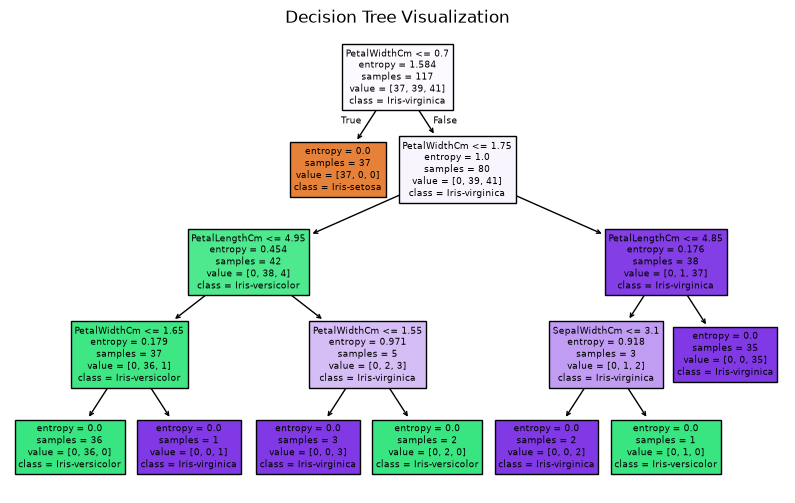

In [ ]:
# Plot the decision tree
plt.figure(figsize=(10, 6))
plot_tree(dt, feature_names=features.columns, class_names=dt.classes_, filled=True)
plt.title("Decision Tree Visualization")
plt.show()

## 7. Model Comparison

Both models are compared using test accuracy, calculated as the proportion of correctly classified samples.

In [ ]:
# Compare models using accuracy
comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Decision Tree"],
    "Accuracy (%)": [round(lr_acc * 100, 2), round(dt_acc * 100, 2)]
})
display(comparison)

,Model,Accuracy (%)
0,Logistic Regression,100.00
1,Decision Tree,96.67


### Observations from Model Comparison:
1. **Overall Accuracy:** On the cleaned dataset, Logistic Regression achieved **100.0%** accuracy, while the Decision Tree achieved **96.67%** accuracy on the test set.
2. **Perfect Classification in Logistic Regression:** Logistic Regression achieved perfect precision, recall, and F1-score (1.00) across all three classes on this test split.
3. **Decision Tree Boundary Separation:** The Decision Tree misclassified only 1 sample between `Iris-versicolor` and `Iris-virginica`, reflecting their slight overlap near boundary measurements.
4. **Impact of Cleaning & Interpretability:** Removing the 3 duplicate rows ensured the models were trained on unique observations (147 rows), and the Decision Tree flowchart provides transparent, interpretable rules (e.g., `PetalLengthCm <= 2.45`).

## 8. Predictions on New Data

The trained models are used to predict the species of a new flower from its four measurements: sepal length, sepal width, petal length, and petal width.

Comparing both predictions demonstrates how trained classifiers can classify new observations.

In [ ]:
# New sample measurements: [SepalLength, SepalWidth, PetalLength, PetalWidth]
sample = [[7.7,3.0,6.1,2.3]]

print("Logistic Regression Prediction:", lr.predict(sample)[0])
print("Decision Tree Prediction      :", dt.predict(sample)[0])

Logistic Regression Prediction: Iris-virginica
Decision Tree Prediction      : Iris-virginica


## 9. Saving Trained Models for Future Evaluation

The trained Logistic Regression and Decision Tree models are saved as pickle (`.pkl`) files so they can be reused in future tasks without training them again.

The `pickle` module serializes Python objects and stores them in files. These saved models can later be loaded into a separate notebook for model evaluation, including accuracy, precision, recall, F1-score, and confusion matrix generation.

**Models being saved:**
- Logistic Regression
- Decision Tree (Entropy criterion)

**Purpose:** To preserve the trained model objects and reuse them in Day 12's model evaluation task.

In [ ]:
# Create a folder for the saved models
model_folder = Path("saved_models")
model_folder.mkdir(exist_ok=True)

# Save the trained Logistic Regression model
with open(model_folder / "logistic_regression.pkl", "wb") as file:
    pickle.dump(lr, file)

# Save the trained Decision Tree model
with open(model_folder / "decision_tree.pkl", "wb") as file:
    pickle.dump(dt, file)

print("Both trained models have been saved successfully!")
print(f"Model files location: {model_folder.resolve()}")


Both trained models have been saved successfully!
Model files location: E:\OneDrive - Indian Oil Corporation Limited\Desktop\AI-ML-Internship\Day 11\saved_models
